In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="xxxxxxxxx")
project = rf.workspace("test2-cedxe").project("mobile-damage-diagnosis-14usw")
version = project.version(1)
dataset = version.download("yolov8", location="raw/damage")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 77.8 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to raw/damage in yolov8:: 100%|██████████| 3806/3806 [00:03<00:00, 1120.36it/s]


In [ ]:
import yaml
print(yaml.safe_load(open("raw/damage/data.yaml"))["names"])

['dead pixel', 'scratch', 'screen crack']


In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="xxxxxxxxxxxx")
project = rf.workspace("sengital-limited-ohknf").project("mobile-phone-detection-5mnmq")
version = project.version(1)
dataset = version.download("yolov8", location="raw/sengital")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to raw/sengital in yolov8:: 100%|██████████| 3814/3814 [00:00<00:00, 5527.42it/s]


In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="xxxxxxxxxxxxx")
project = rf.workspace("20701s-workspace").project("crackedscreen")
version = project.version(2)
dataset = version.download("yolov8", location="raw/cracked")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to raw/cracked in yolov8:: 100%|██████████| 343/343 [00:00<00:00, 5859.06it/s]


In [ ]:
for n in ["sengital", "cracked"]:
    print(n, yaml.safe_load(open(f"raw/{n}/data.yaml"))["names"])

sengital ['burn in', 'case scratch', 'complete', 'dead pixel', 'display problem', 'scratch', 'screen crack']
cracked ['broken phone', 'not broken phone']


In [ ]:
import os, shutil, glob, yaml

UNIFIED = ["crack", "scratch", "display_defect"]
MAP = {
 "damage":  {"screen crack":"crack", "scratch":"scratch", "dead pixel":"display_defect"},
 "sengital":{"screen crack":"crack", "scratch":"scratch", "case scratch":"scratch",
             "dead pixel":"display_defect", "burn in":"display_defect",
             "display problem":"display_defect", "complete":None},
 "cracked": {"not broken phone":None, "broken phone":None},
}
DROP_IF_PRESENT = {"cracked": {"broken phone"}}   # images with these classes are skipped

for split in ["train", "valid", "test"]:
    os.makedirs(f"merged/{split}/images", exist_ok=True)
    os.makedirs(f"merged/{split}/labels", exist_ok=True)

kept, dropped = {}, {}
for ds, m in MAP.items():
    names = yaml.safe_load(open(f"raw/{ds}/data.yaml"))["names"]
    for split in ["train", "valid", "test"]:
        for img in glob.glob(f"raw/{ds}/{split}/images/*"):
            base = os.path.splitext(os.path.basename(img))[0]
            lbl = f"raw/{ds}/{split}/labels/{base}.txt"
            lines = [l.split() for l in open(lbl)] if os.path.exists(lbl) else []
            src_names = {names[int(p[0])] for p in lines}
            if src_names & DROP_IF_PRESENT.get(ds, set()):
                dropped[ds] = dropped.get(ds, 0) + 1
                continue
            out = []
            for p in lines:
                tgt = m.get(names[int(p[0])])
                if tgt:
                    out.append(" ".join([str(UNIFIED.index(tgt))] + p[1:]))
            shutil.copy(img, f"merged/{split}/images/{ds}_{os.path.basename(img)}")
            open(f"merged/{split}/labels/{ds}_{base}.txt", "w").write("\n".join(out))
            kept[ds] = kept.get(ds, 0) + 1

print("kept:", kept, "dropped:", dropped)
yaml.dump({"path":"/content/merged","train":"train/images","val":"valid/images",
           "test":"test/images","names":dict(enumerate(UNIFIED))},
          open("merged/data.yaml","w"))

kept: {'damage': 1901, 'sengital': 1901, 'cracked': 73} dropped: {'cracked': 96}


In [ ]:
from collections import Counter
for split in ["train", "valid", "test"]:
    c, empty = Counter(), 0
    for f in glob.glob(f"merged/{split}/labels/*.txt"):
        rows = [l for l in open(f).read().splitlines() if l.strip()]
        if not rows: empty += 1
        for r in rows: c[UNIFIED[int(r.split()[0])]] += 1
    print(split, dict(c), "empty (OK) images:", empty)

train {'display_defect': 1630, 'crack': 3129, 'scratch': 1744} empty (OK) images: 573
valid {'display_defect': 255, 'scratch': 431, 'crack': 678} empty (OK) images: 199
test {'scratch': 35, 'display_defect': 27, 'crack': 34} empty (OK) images: 27


In [ ]:
!pip -q install imagehash pillow
import imagehash, glob, numpy as np
from PIL import Image

def hashes(ds):
    return {p: imagehash.phash(Image.open(p)).hash.flatten()
            for p in glob.glob(f"raw/{ds}/*/images/*")}

hd, hs = hashes("damage"), hashes("sengital")
S = np.array(list(hs.values()))
match = sum(((S != h).sum(1).min() <= 4) for h in hd.values())
print(f"{match}/{len(hd)} damage images have a near-duplicate in sengital")

1901/1901 damage images have a near-duplicate in sengital


In [ ]:
!rm -rf merged

In [ ]:
import os, shutil, glob, yaml

UNIFIED = ["crack", "scratch", "display_defect"]
MAP = {
 "sengital":{"screen crack":"crack", "scratch":"scratch", "case scratch":"scratch",
             "dead pixel":"display_defect", "burn in":"display_defect",
             "display problem":"display_defect", "complete":None},
 "cracked": {"not broken phone":None, "broken phone":None},
}
DROP_IF_PRESENT = {"cracked": {"broken phone"}}

for split in ["train", "valid", "test"]:
    os.makedirs(f"merged/{split}/images", exist_ok=True)
    os.makedirs(f"merged/{split}/labels", exist_ok=True)

kept, dropped = {}, {}
for ds, m in MAP.items():
    names = yaml.safe_load(open(f"raw/{ds}/data.yaml"))["names"]
    for split in ["train", "valid", "test"]:
        for img in glob.glob(f"raw/{ds}/{split}/images/*"):
            base = os.path.splitext(os.path.basename(img))[0]
            lbl = f"raw/{ds}/{split}/labels/{base}.txt"
            lines = [l.split() for l in open(lbl)] if os.path.exists(lbl) else []
            src_names = {names[int(p[0])] for p in lines}
            if src_names & DROP_IF_PRESENT.get(ds, set()):
                dropped[ds] = dropped.get(ds, 0) + 1
                continue
            out = []
            for p in lines:
                tgt = m.get(names[int(p[0])])
                if tgt:
                    out.append(" ".join([str(UNIFIED.index(tgt))] + p[1:]))
            shutil.copy(img, f"merged/{split}/images/{ds}_{os.path.basename(img)}")
            open(f"merged/{split}/labels/{ds}_{base}.txt", "w").write("\n".join(out))
            kept[ds] = kept.get(ds, 0) + 1

print("kept:", kept, "dropped:", dropped)

kept: {'sengital': 1901, 'cracked': 73} dropped: {'cracked': 96}


In [ ]:
!pip -q install imagehash pillow
import glob, os, shutil, random, imagehash, numpy as np, yaml
from PIL import Image

pairs = []
for split in ["train", "valid", "test"]:
    for img in glob.glob(f"merged/{split}/images/*"):
        base = os.path.splitext(os.path.basename(img))[0]
        pairs.append((img, f"merged/{split}/labels/{base}.txt"))

kept, hashes = [], np.empty((0, 64), dtype=bool)
for img, lbl in pairs:
    h = imagehash.phash(Image.open(img)).hash.flatten()
    if len(hashes) and (hashes != h).sum(1).min() <= 4:
        continue
    hashes = np.vstack([hashes, h]); kept.append((img, lbl))
print(f"{len(pairs)} -> {len(kept)} after dedupe")

random.seed(42); random.shuffle(kept)
n = len(kept)
bounds = {"train": (0, int(.8*n)), "valid": (int(.8*n), int(.9*n)), "test": (int(.9*n), n)}

for split, (a, b) in bounds.items():
    os.makedirs(f"final/{split}/images", exist_ok=True)
    os.makedirs(f"final/{split}/labels", exist_ok=True)
    for img, lbl in kept[a:b]:
        shutil.copy(img, f"final/{split}/images/")
        shutil.copy(lbl, f"final/{split}/labels/")

yaml.dump({"path":"/content/final","train":"train/images","val":"valid/images",
           "test":"test/images","names":dict(enumerate(UNIFIED))}, open("final/data.yaml","w"))
print({s: len(os.listdir(f"final/{s}/images")) for s in bounds})

1974 -> 1884 after dedupe
{'train': 1507, 'valid': 188, 'test': 189}


In [ ]:
from collections import Counter
import glob

for split in ["train", "valid", "test"]:
    c, empty = Counter(), 0
    for f in glob.glob(f"final/{split}/labels/*.txt"):
        rows = [l for l in open(f).read().splitlines() if l.strip()]
        if not rows:
            empty += 1
        for r in rows:
            c[UNIFIED[int(r.split()[0])]] += 1
    print(split, dict(c), "empty (OK) images:", empty)

train {'crack': 1554, 'display_defect': 1003, 'scratch': 798} empty (OK) images: 282
valid {'display_defect': 148, 'scratch': 87, 'crack': 160} empty (OK) images: 39
test {'crack': 198, 'scratch': 110, 'display_defect': 102} empty (OK) images: 34


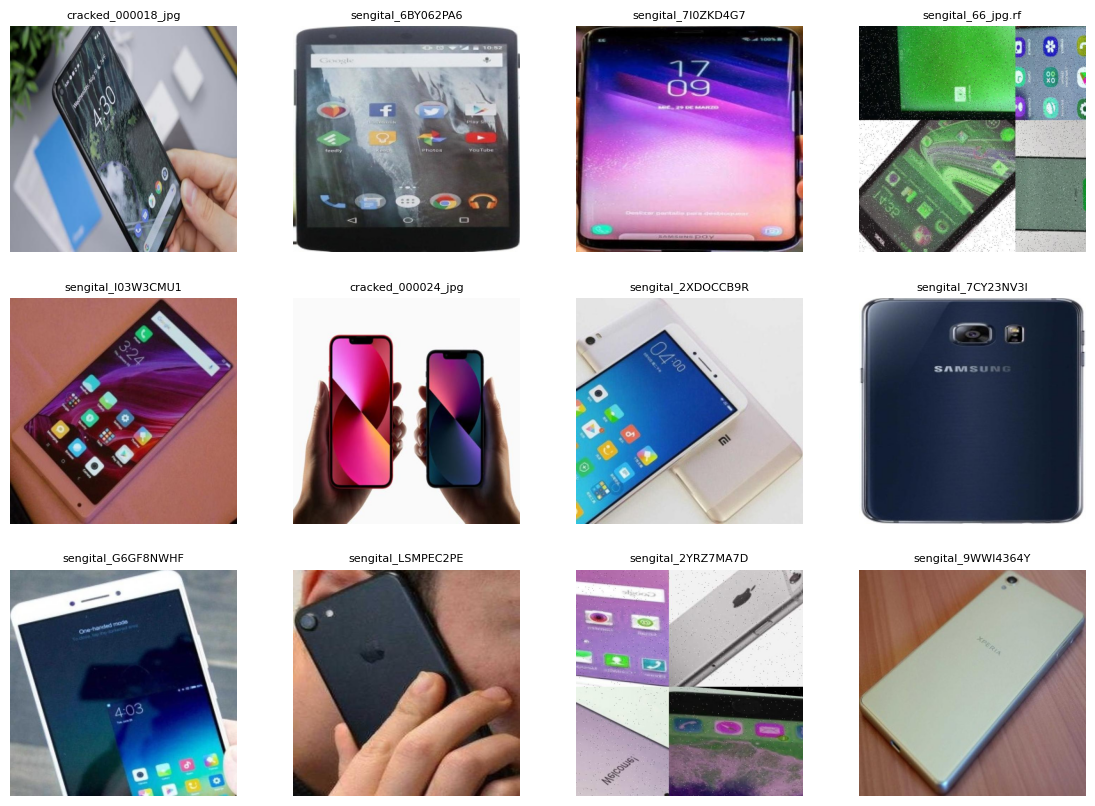

In [ ]:
import glob, random, os
import matplotlib.pyplot as plt
from PIL import Image

empties = [f for f in glob.glob("final/train/labels/*.txt") if not open(f).read().strip()]
random.seed(1)
sample = random.sample(empties, 12)

fig, ax = plt.subplots(3, 4, figsize=(14, 10))
for a, f in zip(ax.flat, sample):
    base = os.path.splitext(os.path.basename(f))[0]
    img_path = glob.glob(f"final/train/images/{base}.*")[0]
    a.imshow(Image.open(img_path))
    a.set_title(base[:18], fontsize=8)
    a.axis("off")
plt.show()

In [ ]:
!pip -q install ultralytics
from ultralytics import YOLO

model = YOLO("yolov8n.pt")
model.train(
    data="/content/final/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    project="runs",
    name="baseline",
    seed=42,
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/final/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x790e3c9407c0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

In [ ]:
import glob, os, numpy as np
from ultralytics import YOLO

model = YOLO("/content/runs/detect/runs/baseline/weights/best.pt")

# Box-level metrics on the held-out test split
model.val(data="/content/final/data.yaml", split="test")

# Image-level verdict: NOT OK if any box passes the confidence threshold
scores, truth = [], []
for img in glob.glob("final/test/images/*"):
    base = os.path.splitext(os.path.basename(img))[0]
    truth.append(bool(open(f"final/test/labels/{base}.txt").read().strip()))
    r = model.predict(img, conf=0.05, verbose=False)[0]
    scores.append(float(r.boxes.conf.max()) if len(r.boxes) else 0.0)
scores, truth = np.array(scores), np.array(truth)

for t in [0.15, 0.25, 0.40, 0.50]:
    pred = scores >= t
    tp = (pred & truth).sum(); fp = (pred & ~truth).sum()
    fn = (~pred & truth).sum(); tn = (~pred & ~truth).sum()
    print(f"thr {t}: damaged caught {tp}/{tp+fn} | OK phones passed {tn}/{tn+fp} | precision {tp/max(tp+fp,1):.2f}")

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1472.7±606.2 MB/s, size: 66.8 KB)
val: Scanning /content/final/test/labels... 189 images, 34 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 189/189 2.2Kit/s 0.1s
val: New cache created: /content/final/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 3.0it/s 4.0s
                   all        189        410      0.783      0.644      0.724      0.415
                 crack        101        198      0.724      0.525      0.615      0.359
               scratch         48        110      0.837      0.691      0.782      0.387
        display_defect         58        102      0.789      0.716      0.773        0.5
Speed: 2.7ms preprocess, 5.4ms inference, 0.0ms loss, 3.5ms postprocess per image
Results

10 test images with a missed crack


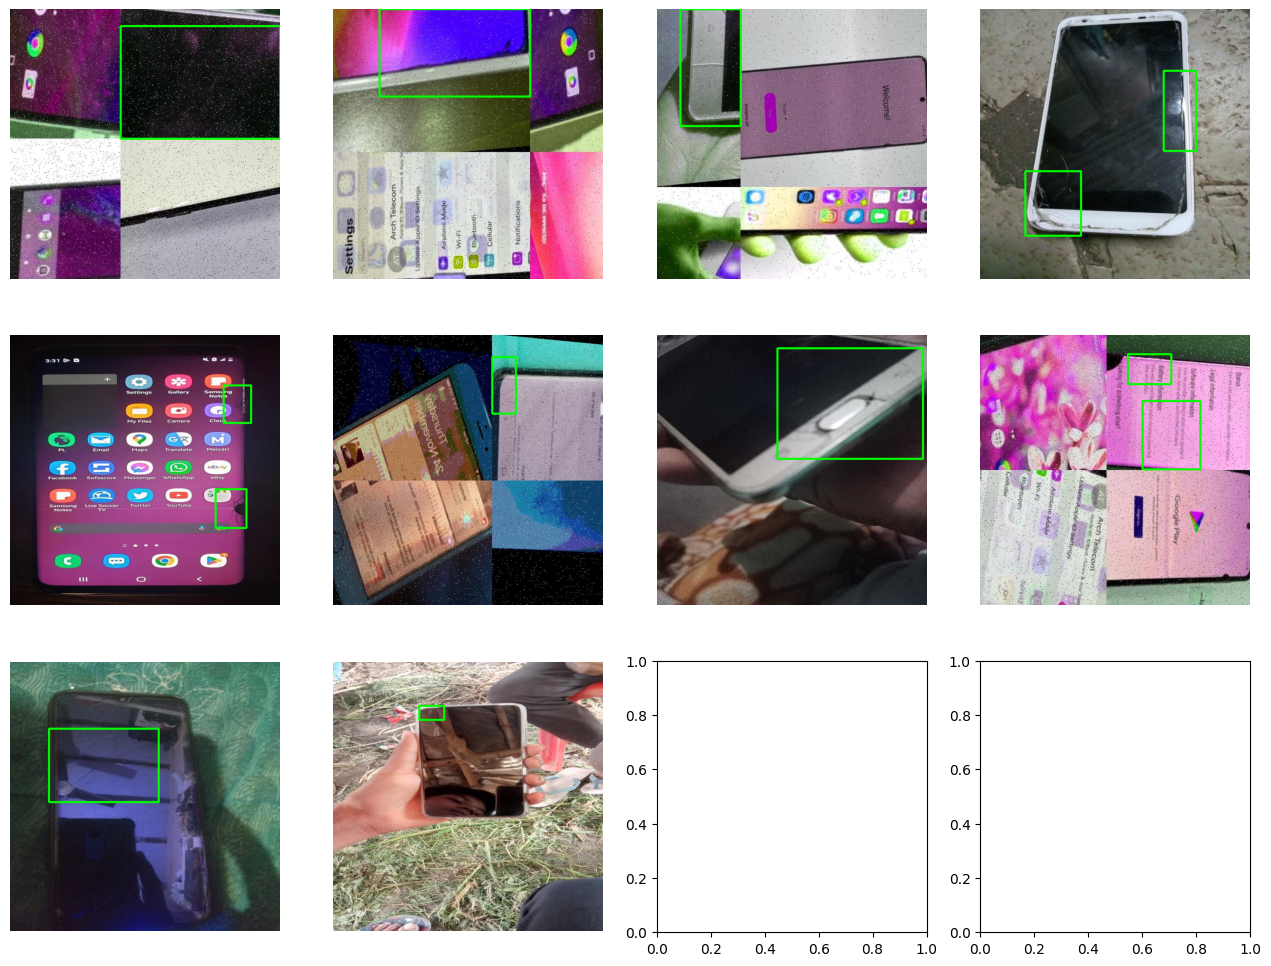

In [ ]:
import cv2, random
import matplotlib.pyplot as plt

misses = []
for img in glob.glob("final/test/images/*"):
    base = os.path.splitext(os.path.basename(img))[0]
    gt = [l.split() for l in open(f"final/test/labels/{base}.txt") if l.strip()]
    if not any(g[0] == "0" for g in gt):
        continue
    r = model.predict(img, conf=0.25, verbose=False)[0]
    if not any(int(c) == 0 for c in r.boxes.cls):
        misses.append((img, gt))
print(len(misses), "test images with a missed crack")

random.seed(0)
fig, ax = plt.subplots(3, 4, figsize=(16, 12))
for a, (img, gt) in zip(ax.flat, random.sample(misses, min(12, len(misses)))):
    im = cv2.imread(img); h, w = im.shape[:2]
    for g in gt:
        if g[0] == "0":
            x, y, bw, bh = map(float, g[1:5])
            cv2.rectangle(im, (int((x-bw/2)*w), int((y-bh/2)*h)),
                          (int((x+bw/2)*w), int((y+bh/2)*h)), (0, 255, 0), 3)
    a.imshow(im[:, :, ::-1]); a.axis("off")
plt.show()

In [ ]:
import numpy as np, glob, os

caught, missed = [], []
for img in glob.glob("final/test/images/*"):
    base = os.path.splitext(os.path.basename(img))[0]
    gt = [l.split() for l in open(f"final/test/labels/{base}.txt")
          if l.strip() and l.split()[0] == "0"]
    if not gt:
        continue
    r = model.predict(img, conf=0.25, verbose=False)[0]
    cls = r.boxes.cls.cpu().numpy()
    pred = r.boxes.xywhn.cpu().numpy()[cls == 0]
    for g in gt:
        x, y, w, h = map(float, g[1:5])
        hit = any(abs(px - x) < w/2 and abs(py - y) < h/2 for px, py, _, _ in pred)
        (caught if hit else missed).append(w * h)

caught, missed = np.array(caught), np.array(missed)
print(f"crack boxes: {len(caught)} caught, {len(missed)} missed")
print(f"median box area (fraction of image)  caught: {np.median(caught):.3f}  missed: {np.median(missed):.3f}")
print(f"boxes under 2% of the image  caught: {(caught<0.02).mean():.0%}  missed: {(missed<0.02).mean():.0%}")

crack boxes: 125 caught, 73 missed
median box area (fraction of image)  caught: 0.135  missed: 0.032
boxes under 2% of the image  caught: 6%  missed: 40%


In [ ]:
from ultralytics import YOLO

model960 = YOLO("yolov8n.pt")
model960.train(
    data="/content/final/data.yaml",
    epochs=50,
    imgsz=960,
    batch=16,
    project="runs",
    name="imgsz960",
    seed=42,
)

best960 = YOLO("/content/runs/detect/runs/imgsz960/weights/best.pt")
best960.val(data="/content/final/data.yaml", split="test", imgsz=960)

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/final/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=imgsz960, nbs=64, nms=None, opset=None, optimize=False, optimize

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x790e44156dd0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

In [ ]:
import glob, os, numpy as np
from ultralytics import YOLO

m960 = YOLO("/content/runs/detect/runs/imgsz960/weights/best.pt")
scores, truth = [], []
for img in glob.glob("final/test/images/*"):
    base = os.path.splitext(os.path.basename(img))[0]
    truth.append(bool(open(f"final/test/labels/{base}.txt").read().strip()))
    r = m960.predict(img, conf=0.05, imgsz=960, verbose=False)[0]
    scores.append(float(r.boxes.conf.max()) if len(r.boxes) else 0.0)
scores, truth = np.array(scores), np.array(truth)

for t in [0.15, 0.25, 0.40, 0.50]:
    pred = scores >= t
    tp = (pred & truth).sum(); fp = (pred & ~truth).sum()
    fn = (~pred & truth).sum(); tn = (~pred & ~truth).sum()
    print(f"thr {t}: damaged caught {tp}/{tp+fn} | OK phones passed {tn}/{tn+fp} | precision {tp/max(tp+fp,1):.2f}")

thr 0.15: damaged caught 149/155 | OK phones passed 26/34 | precision 0.95
thr 0.25: damaged caught 143/155 | OK phones passed 30/34 | precision 0.97
thr 0.4: damaged caught 129/155 | OK phones passed 34/34 | precision 1.00
thr 0.5: damaged caught 111/155 | OK phones passed 34/34 | precision 1.00


In [ ]:
pip install ultralytics opencv-python

In [ ]:
!pip -q install gradio
import collections
import gradio as gr
from ultralytics import YOLO

model = YOLO("/content/runs/detect/runs/baseline/weights/best.pt")
CONF, WINDOW, NEED = 0.25, 10, 4
hist = collections.deque(maxlen=WINDOW)

def check(frame):
    if frame is None:
        return None, "No frame"
    r = model.predict(frame, conf=CONF, imgsz=640, verbose=False)[0]
    hist.append(len(r.boxes) > 0)
    damaged = sum(hist) >= NEED
    verdict = "NOT OK - damage detected" if damaged else "OK"
    return r.plot()[:, :, ::-1], verdict   # BGR -> RGB for display

with gr.Blocks() as demo:
    gr.Markdown("## Phone damage check (YOLOv8n)")
    cam = gr.Image(sources=["webcam"], streaming=True, label="Webcam")
    out = gr.Image(label="Detections")
    verdict = gr.Textbox(label="Verdict")
    cam.stream(check, cam, [out, verdict], stream_every=0.3, time_limit=120)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://07ea7c88a875c3d8c8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import collections, cv2
import gradio as gr
from ultralytics import YOLO

damage_model = YOLO("/content/runs/detect/runs/baseline/weights/best.pt")
phone_model = YOLO("yolov8n.pt")          # COCO model; class 67 = cell phone
PHONE_CLS, PHONE_CONF = 67, 0.30
CONF, WINDOW, NEED = 0.25, 10, 4
hist = collections.deque(maxlen=WINDOW)

def check(frame):
    if frame is None:
        return None, "No frame"
    bgr = frame[:, :, ::-1].copy()                      # Gradio gives RGB; YOLO expects BGR
    H, W = bgr.shape[:2]

    p = phone_model.predict(bgr, conf=PHONE_CONF, classes=[PHONE_CLS], verbose=False)[0]
    if len(p.boxes) == 0:
        hist.clear()
        return frame, "No phone detected"

    best = int(p.boxes.conf.argmax())
    x1, y1, x2, y2 = map(int, p.boxes.xyxy[best].tolist())
    pad = int(0.05 * max(x2 - x1, y2 - y1))
    x1, y1, x2, y2 = max(0, x1 - pad), max(0, y1 - pad), min(W, x2 + pad), min(H, y2 + pad)
    cv2.rectangle(bgr, (x1, y1), (x2, y2), (0, 200, 0), 2)

    d = damage_model.predict(bgr[y1:y2, x1:x2], conf=CONF, imgsz=640, verbose=False)[0]
    for b in d.boxes:
        bx1, by1, bx2, by2 = map(int, b.xyxy[0].tolist())
        cv2.rectangle(bgr, (x1 + bx1, y1 + by1), (x1 + bx2, y1 + by2), (0, 0, 255), 2)
        label = f"{d.names[int(b.cls)]} {float(b.conf):.2f}"
        cv2.putText(bgr, label, (x1 + bx1, max(15, y1 + by1 - 5)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)

    hist.append(len(d.boxes) > 0)
    verdict = "NOT OK - damage detected" if sum(hist) >= NEED else "OK"
    return bgr[:, :, ::-1], verdict

with gr.Blocks() as demo:
    gr.Markdown("## Phone damage check (phone detector + YOLOv8n damage model)")
    cam = gr.Image(sources=["webcam"], streaming=True, label="Webcam")
    out = gr.Image(label="Detections")
    verdict = gr.Textbox(label="Verdict")
    cam.stream(check, cam, [out, verdict], stream_every=0.3, time_limit=120)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://fa41351b2569b87b35.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import collections, cv2
import gradio as gr
from ultralytics import YOLO

damage_model = YOLO("/content/runs/detect/runs/baseline/weights/best.pt")
phone_model = YOLO("yolov8n.pt")
PHONE_CLS, PHONE_CONF = 67, 0.20
CONF = 0.25            # damage threshold when a phone box is found
FALLBACK_CONF = 0.40   # stricter threshold on the full frame when no phone box
WINDOW, NEED = 6, 2    # NOT OK if damage in 2 of the last 6 frames
MISS_LIMIT = 5         # frames without a phone before the history resets
hist = collections.deque(maxlen=WINDOW)
misses = 0

def check(frame):
    global misses
    if frame is None:
        return None, "No frame"
    bgr = frame[:, :, ::-1].copy()
    H, W = bgr.shape[:2]
    ox, oy = 0, 0

    p = phone_model.predict(bgr, conf=PHONE_CONF, classes=[PHONE_CLS], verbose=False)[0]
    if len(p.boxes) > 0:
        best = int(p.boxes.conf.argmax())
        x1, y1, x2, y2 = map(int, p.boxes.xyxy[best].tolist())
        pad = int(0.05 * max(x2 - x1, y2 - y1))
        x1, y1, x2, y2 = max(0, x1 - pad), max(0, y1 - pad), min(W, x2 + pad), min(H, y2 + pad)
        cv2.rectangle(bgr, (x1, y1), (x2, y2), (0, 200, 0), 2)
        d = damage_model.predict(bgr[y1:y2, x1:x2], conf=CONF, imgsz=640, verbose=False)[0]
        ox, oy = x1, y1
    else:
        d = damage_model.predict(bgr, conf=FALLBACK_CONF, imgsz=640, verbose=False)[0]
        if len(d.boxes) == 0:
            misses += 1
            if misses >= MISS_LIMIT:
                hist.clear()
            return frame, "No phone detected"

    misses = 0
    for b in d.boxes:
        bx1, by1, bx2, by2 = map(int, b.xyxy[0].tolist())
        cv2.rectangle(bgr, (ox + bx1, oy + by1), (ox + bx2, oy + by2), (0, 0, 255), 2)
        cv2.putText(bgr, f"{d.names[int(b.cls)]} {float(b.conf):.2f}",
                    (ox + bx1, max(15, oy + by1 - 5)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)

    hist.append(len(d.boxes) > 0)
    n = sum(hist)
    verdict = "NOT OK - damage detected" if n >= NEED else "OK"
    return bgr[:, :, ::-1], f"{verdict}   (damage in {n}/{len(hist)} recent frames)"

with gr.Blocks() as demo:
    gr.Markdown("## Phone damage check (phone detector + YOLOv8n damage model)")
    cam = gr.Image(sources=["webcam"], streaming=True, label="Webcam")
    out = gr.Image(label="Detections")
    verdict = gr.Textbox(label="Verdict")
    cam.stream(check, cam, [out, verdict], stream_every=0.3, time_limit=120)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://58c5bf6149e41211cd.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import collections, time, cv2
import gradio as gr
from ultralytics import YOLO

damage_model = YOLO("/content/runs/detect/runs/baseline/weights/best.pt")
phone_model = YOLO("yolov8n.pt")
PHONE_CLS, PHONE_CONF = 67, 0.20
CONF, FALLBACK_CONF = 0.25, 0.40
WINDOW, NEED, MISS_LIMIT = 6, 2, 5
MAX_W = 480                      # downscale frames before inference
hist = collections.deque(maxlen=WINDOW)
misses = 0

def check(frame):
    global misses
    if frame is None:
        return None, "No frame"
    t0 = time.time()
    h0, w0 = frame.shape[:2]
    if w0 > MAX_W:
        frame = cv2.resize(frame, (MAX_W, int(h0 * MAX_W / w0)))
    bgr = frame[:, :, ::-1].copy()
    H, W = bgr.shape[:2]
    ox, oy = 0, 0

    p = phone_model.predict(bgr, conf=PHONE_CONF, classes=[PHONE_CLS],
                            imgsz=320, half=True, device=0, verbose=False)[0]
    if len(p.boxes) > 0:
        best = int(p.boxes.conf.argmax())
        x1, y1, x2, y2 = map(int, p.boxes.xyxy[best].tolist())
        pad = int(0.05 * max(x2 - x1, y2 - y1))
        x1, y1, x2, y2 = max(0, x1 - pad), max(0, y1 - pad), min(W, x2 + pad), min(H, y2 + pad)
        cv2.rectangle(bgr, (x1, y1), (x2, y2), (0, 200, 0), 2)
        d = damage_model.predict(bgr[y1:y2, x1:x2], conf=CONF, imgsz=640,
                                 half=True, device=0, verbose=False)[0]
        ox, oy = x1, y1
    else:
        d = damage_model.predict(bgr, conf=FALLBACK_CONF, imgsz=640,
                                 half=True, device=0, verbose=False)[0]
        if len(d.boxes) == 0:
            misses += 1
            if misses >= MISS_LIMIT:
                hist.clear()
            ms = (time.time() - t0) * 1000
            return bgr[:, :, ::-1], f"No phone detected   [server {ms:.0f} ms]"

    misses = 0
    for b in d.boxes:
        bx1, by1, bx2, by2 = map(int, b.xyxy[0].tolist())
        cv2.rectangle(bgr, (ox + bx1, oy + by1), (ox + bx2, oy + by2), (0, 0, 255), 2)
        cv2.putText(bgr, f"{d.names[int(b.cls)]} {float(b.conf):.2f}",
                    (ox + bx1, max(15, oy + by1 - 5)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2)

    hist.append(len(d.boxes) > 0)
    n = sum(hist)
    verdict = "NOT OK - damage detected" if n >= NEED else "OK"
    ms = (time.time() - t0) * 1000
    return bgr[:, :, ::-1], f"{verdict}   (damage {n}/{len(hist)})   [server {ms:.0f} ms]"

with gr.Blocks() as demo:
    gr.Markdown("## Phone damage check")
    cam = gr.Image(sources=["webcam"], streaming=True, label="Webcam")
    out = gr.Image(label="Detections")
    verdict = gr.Textbox(label="Verdict")
    cam.stream(check, cam, [out, verdict], stream_every=0.5, time_limit=120,
               concurrency_limit=1)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://67c4de0834b0de9df5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
!pip -q install onnx onnxruntime
import glob, time, os, numpy as np
from ultralytics import YOLO

pt = YOLO("/content/runs/detect/runs/baseline/weights/best.pt")
onnx_path = pt.export(format="onnx", imgsz=640, simplify=True)
onnx_model = YOLO(onnx_path)
print("ONNX file size (MB):", round(os.path.getsize(onnx_path) / 1e6, 1))

imgs = sorted(glob.glob("final/test/images/*"))[:60]

def bench(m, name):
    for im in imgs[:5]:                       # warm-up runs, not timed
        m.predict(im, imgsz=640, device="cpu", verbose=False)
    ts = []
    for im in imgs:
        t = time.perf_counter()
        m.predict(im, imgsz=640, device="cpu", verbose=False)
        ts.append((time.perf_counter() - t) * 1000)
    ts = np.array(ts)
    print(f"{name}: median {np.median(ts):.0f} ms | p95 {np.percentile(ts, 95):.0f} ms | ~{1000/np.median(ts):.1f} FPS")

print("CPU cores:", os.cpu_count())
bench(pt, "PyTorch (CPU)")
bench(onnx_model, "ONNX (CPU)")

# Accuracy check: the ONNX model should match the PyTorch test results
onnx_model.val(data="/content/final/data.yaml", split="test", imgsz=640, device="cpu")

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs

PyTorch: starting from '/content/runs/detect/runs/baseline/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (6.2 MB)
requirements: Ultralytics requirement ['onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 10 packages in 333ms
Prepared 2 packages in 51ms
Installed 2 packages in 6ms
 + colorama==0.4.6
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 0.8s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 2.7s, saved as '/content/runs/d

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x790dec802200>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

In [ ]:
import glob, os, numpy as np, imagehash
from PIL import Image
from collections import Counter

UNIFIED = ["crack", "scratch", "display_defect"]
stems, hashes = {}, {}
for s in ["train", "valid", "test"]:
    imgs = glob.glob(f"final/{s}/images/*")
    lbls = glob.glob(f"final/{s}/labels/*.txt")
    stems[s] = {os.path.splitext(os.path.basename(p))[0] for p in imgs}
    c, empty = Counter(), 0
    for f in lbls:
        rows = [l for l in open(f).read().splitlines() if l.strip()]
        empty += not rows
        for r in rows:
            c[UNIFIED[int(r.split()[0])]] += 1
    print(s, "images:", len(imgs), "labels:", len(lbls), dict(c), "empty:", empty)
    hashes[s] = np.array([imagehash.phash(Image.open(p)).hash.flatten() for p in imgs])

for a, b in [("train", "valid"), ("train", "test"), ("valid", "test")]:
    print(a, "&", b, "same filename:", len(stems[a] & stems[b]))
for s in ["valid", "test"]:
    near = sum(((hashes["train"] != h).sum(1).min() <= 4) for h in hashes[s])
    print(f"{s}: {near}/{len(hashes[s])} images have a near-duplicate in train")

train images: 1507 labels: 1507 {'crack': 1554, 'display_defect': 1003, 'scratch': 798} empty: 282
valid images: 188 labels: 188 {'display_defect': 148, 'scratch': 87, 'crack': 160} empty: 39
test images: 189 labels: 189 {'crack': 198, 'scratch': 110, 'display_defect': 102} empty: 34
train & valid same filename: 0
train & test same filename: 0
valid & test same filename: 0
valid: 0/188 images have a near-duplicate in train
test: 0/189 images have a near-duplicate in train


In [ ]:
import glob, os, shutil, random, json, imagehash, numpy as np, yaml
from collections import Counter
from PIL import Image

UNIFIED = ["crack", "scratch", "display_defect"]
shutil.rmtree("final_old", ignore_errors=True)
if os.path.exists("final"):
    os.rename("final", "final_old")

pairs = []
for split in ["train", "valid", "test"]:
    for img in glob.glob(f"merged/{split}/images/*"):
        base = os.path.splitext(os.path.basename(img))[0]
        pairs.append((img, f"merged/{split}/labels/{base}.txt"))
pairs.sort(key=lambda p: os.path.basename(p[0]))      # fixed order

kept, hashes = [], np.empty((0, 64), dtype=bool)
for img, lbl in pairs:
    h = imagehash.phash(Image.open(img)).hash.flatten()
    if len(hashes) and (hashes != h).sum(1).min() <= 4:
        continue
    hashes = np.vstack([hashes, h]); kept.append((img, lbl))
print(f"{len(pairs)} -> {len(kept)} after dedupe")

random.Random(42).shuffle(kept)
n = len(kept)
bounds = {"train": (0, int(.8*n)), "valid": (int(.8*n), int(.9*n)), "test": (int(.9*n), n)}

manifest = {}
for split, (a, b) in bounds.items():
    os.makedirs(f"final/{split}/images"); os.makedirs(f"final/{split}/labels")
    manifest[split] = []
    for img, lbl in kept[a:b]:
        shutil.copy(img, f"final/{split}/images/"); shutil.copy(lbl, f"final/{split}/labels/")
        manifest[split].append(os.path.basename(img))
json.dump(manifest, open("splits.json", "w"))
yaml.dump({"path": "/content/final", "train": "train/images", "val": "valid/images",
           "test": "test/images", "names": dict(enumerate(UNIFIED))}, open("final/data.yaml", "w"))

for s in ["train", "valid", "test"]:
    c, empty = Counter(), 0
    for f in glob.glob(f"final/{s}/labels/*.txt"):
        rows = [l for l in open(f).read().splitlines() if l.strip()]
        empty += not rows
        for r in rows: c[UNIFIED[int(r.split()[0])]] += 1
    print(s, len(os.listdir(f"final/{s}/images")), dict(c), "empty:", empty)

1974 -> 1884 after dedupe
train 1507 {'crack': 1525, 'display_defect': 1008, 'scratch': 788} empty: 276
valid 188 {'crack': 196, 'scratch': 98, 'display_defect': 114} empty: 39
test 189 {'display_defect': 132, 'crack': 191, 'scratch': 97} empty: 40


In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")
model.train(
    data="/content/final/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    project="runs",
    name="baseline_v2",
    seed=42,
)

best = YOLO("/content/runs/detect/runs/baseline_v2/weights/best.pt")
print("=== VALID ===")
best.val(data="/content/final/data.yaml", split="val", imgsz=640)
print("=== TEST (report these) ===")
best.val(data="/content/final/data.yaml", split="test", imgsz=640)

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/final/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline_v2, nbs=64, nms=None, opset=None, optimize=False, optim

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x790deca0c910>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import glob, os, numpy as np
from ultralytics import YOLO

m = YOLO("/content/runs/detect/runs/baseline_v2/weights/best.pt")
scores, truth = [], []
for img in sorted(glob.glob("final/test/images/*")):
    base = os.path.splitext(os.path.basename(img))[0]
    truth.append(bool(open(f"final/test/labels/{base}.txt").read().strip()))
    r = m.predict(img, conf=0.05, imgsz=640, verbose=False)[0]
    scores.append(float(r.boxes.conf.max()) if len(r.boxes) else 0.0)
scores, truth = np.array(scores), np.array(truth)
print("test images:", len(truth), "| damaged:", truth.sum(), "| OK:", (~truth).sum())

for t in [0.15, 0.25, 0.40, 0.50]:
    pred = scores >= t
    tp = (pred & truth).sum(); fp = (pred & ~truth).sum()
    fn = (~pred & truth).sum(); tn = (~pred & ~truth).sum()
    print(f"thr {t}: damaged caught {tp}/{tp+fn} | OK phones passed {tn}/{tn+fp} | precision {tp/max(tp+fp,1):.2f}")

test images: 189 | damaged: 149 | OK: 40
thr 0.15: damaged caught 140/149 | OK phones passed 33/40 | precision 0.95
thr 0.25: damaged caught 137/149 | OK phones passed 35/40 | precision 0.96
thr 0.4: damaged caught 126/149 | OK phones passed 37/40 | precision 0.98
thr 0.5: damaged caught 113/149 | OK phones passed 37/40 | precision 0.97


In [ ]:
!pip -q install onnx onnxruntime onnxslim
import os, shutil
from ultralytics import YOLO

os.makedirs("export", exist_ok=True)

pt = YOLO("/content/runs/detect/runs/baseline_v2/weights/best.pt")
p = pt.export(format="onnx", imgsz=640, opset=12, simplify=True)
shutil.copy(p, "export/damage_640.onnx")

print("=== ONNX damage model on the TEST split (compare with PyTorch: all mAP50 0.635) ===")
YOLO("export/damage_640.onnx").val(data="/content/final/data.yaml", split="test", imgsz=640, device="cpu")

q = YOLO("yolov8n.pt").export(format="onnx", imgsz=640, opset=12, simplify=True)
shutil.copy(q, "export/phone_coco_640.onnx")

for f in ["damage_640.onnx", "phone_coco_640.onnx"]:
    print(f, round(os.path.getsize(f"export/{f}") / 1e6, 1), "MB")

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs

PyTorch: starting from '/content/runs/detect/runs/baseline_v2/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (6.2 MB)

ONNX: starting export with onnx 1.23.2 opset 12...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 1.9s, saved as '/content/runs/detect/runs/baseline_v2/weights/best.onnx' (12.2 MB)

Export complete (2.9s)
Results saved to /content/runs/detect/runs/baseline_v2/weights/best.onnx
Predict:         yolo predict task=detect model=/content/runs/detect/runs/baseline_v2/weights/best.onnx imgsz=640 
Validate:        yolo val task=detect model=/content/runs/detect/runs/baseline_v2/weights/best.onnx imgsz=640 data=/content/final/data.yaml 
Visualize:       https://netron.app
=== ONNX damage model on the TEST split (compare with PyTorch: all mAP50 0.635) ===
Ul